# MNR UNIVERSITY
### School of Engineering, Technology & Artificial Intelligence
## Machine Learning Mini Project (25CSM201) — 2nd Year, 1st Semester
---
# Employee Attrition Prediction Using Machine Learning
**An End-to-End Supervised Classification Benchmark on Enterprise Workforce Data**

- **Team Members:**
  1. **B. Sam Soloman** — Roll No: `25RBAIM0021` (Section: A)
  2. **Thakur Narsingh Singh** — Roll No: `25RBAIM0027` (Section: A)
- **Branch:** B. Tech (Hons.) / CSE (AI & ML)
- **Project Guide:** Dr. M. Praveen
- **Experiment:** Experiment 30 — End-to-End Machine Learning Solution using a Real-World Dataset
---

## 1. Project Overview & Problem Statement

Workforce attrition poses a substantial financial and operational burden on modern organizations. Industry estimates show that replacing a departed knowledge worker incurs costs between **50% to 200%** of their annual compensation.

### Objectives:
1. Ingest and audit the canonical **IBM HR Analytics Employee Attrition & Performance Dataset** (1,470 records, 30 features).
2. Construct a **leakage-free preprocessing pipeline** integrating `StandardScaler` and `LabelEncoder`.
3. Train, benchmark, and cross-validate **6 diverse supervised classification algorithms**:
   - Logistic Regression
   - Decision Tree Classifier
   - Random Forest Classifier
   - K-Nearest Neighbors (KNN)
   - Support Vector Machine (SVM - RBF Kernel)
   - Gaussian Naive Bayes
4. Evaluate performance using balanced metrics: **Accuracy, Precision, Recall, F1-Score, and ROC-AUC**.
5. Determine the key organizational drivers of turnover through **Gini feature importance ranking**.
6. Demonstrate **real-time single employee flight risk inference** with calibrated class probabilities.

In [2]:
# 2. Imports and Environment Setup
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve, classification_report
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10
print('Libraries imported successfully!')

Libraries imported successfully!


## 3. Dataset Loading, Inspection, and Auditing

In [3]:
# Load Dataset
dataset_path = 'attrition.csv' if os.path.exists('attrition.csv') else 'data/attrition.csv'
df = pd.read_csv(dataset_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing / Null Values: {df.isnull().sum().sum()}")
df.head()

Dataset Shape: 1470 rows, 35 columns
Missing / Null Values: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### 3.1 Data Sanitization & Constant Column Removal
Columns with zero variance or arbitrary unique identifiers (`EmployeeCount`, `EmployeeNumber`, `Over18`, `StandardHours`) convey zero predictive entropy and are discarded.

In [4]:
# Drop non-informative constant columns
drop_cols = ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']
df_clean = df.drop(columns=[c for c in drop_cols if c in df.columns])
print(f"Cleaned Dataset Shape: {df_clean.shape} (30 predictive features + 1 target)")

Cleaned Dataset Shape: (1470, 31) (30 predictive features + 1 target)


## 4. Exploratory Data Analysis (EDA)

Class Counts:
 Attrition
No     1233
Yes     237
Name: count, dtype: int64


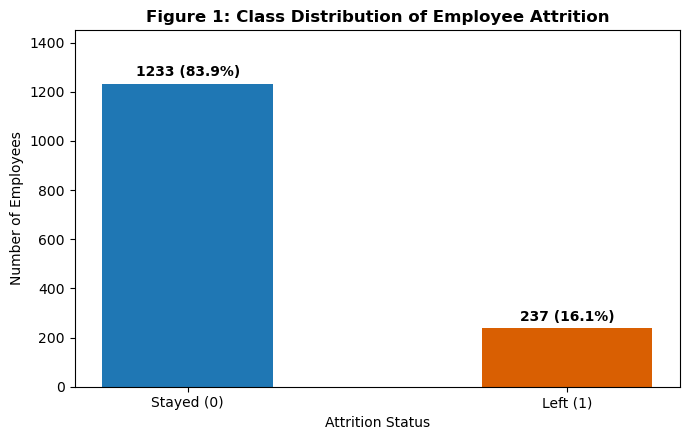

In [5]:
# Class Distribution (Target Variable)
class_counts = df_clean['Attrition'].value_counts()
print("Class Counts:\n", class_counts)

plt.figure(figsize=(7, 4.5))
bars = plt.bar(['Stayed (0)', 'Left (1)'], 
               [class_counts.get('No', 0), class_counts.get('Yes', 0)], 
               color=['#1f77b4', '#d95f02'], width=0.45)
plt.title('Figure 1: Class Distribution of Employee Attrition', fontsize=12, fontweight='bold')
plt.xlabel('Attrition Status')
plt.ylabel('Number of Employees')
plt.ylim(0, 1450)
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df_clean)) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 20, f'{yval} ({pct:.1f}%)', 
             ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

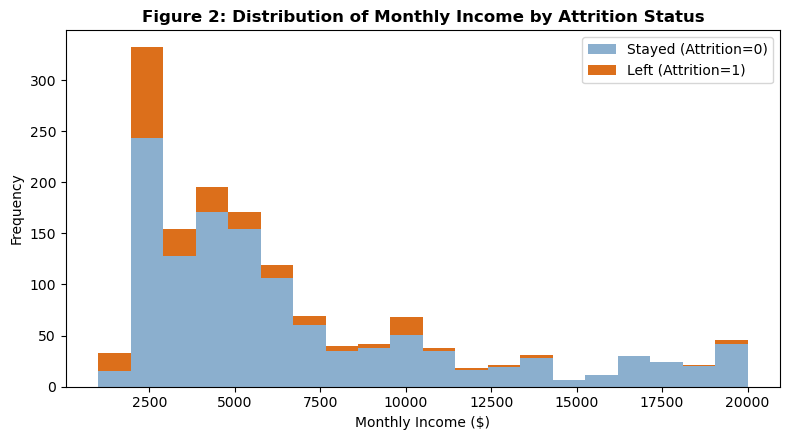

In [6]:
# Monthly Income Distribution by Attrition Status
plt.figure(figsize=(8, 4.5))
plt.hist([df[df['Attrition']=='No']['MonthlyIncome'], df[df['Attrition']=='Yes']['MonthlyIncome']],
         bins=20, stacked=True, color=['#7ea6c9', '#d95f02'], 
         label=['Stayed (Attrition=0)', 'Left (Attrition=1)'], alpha=0.9)
plt.title('Figure 2: Distribution of Monthly Income by Attrition Status', fontsize=12, fontweight='bold')
plt.xlabel('Monthly Income ($)')
plt.ylabel('Frequency')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 5. Categorical Encoding & Correlation Analysis

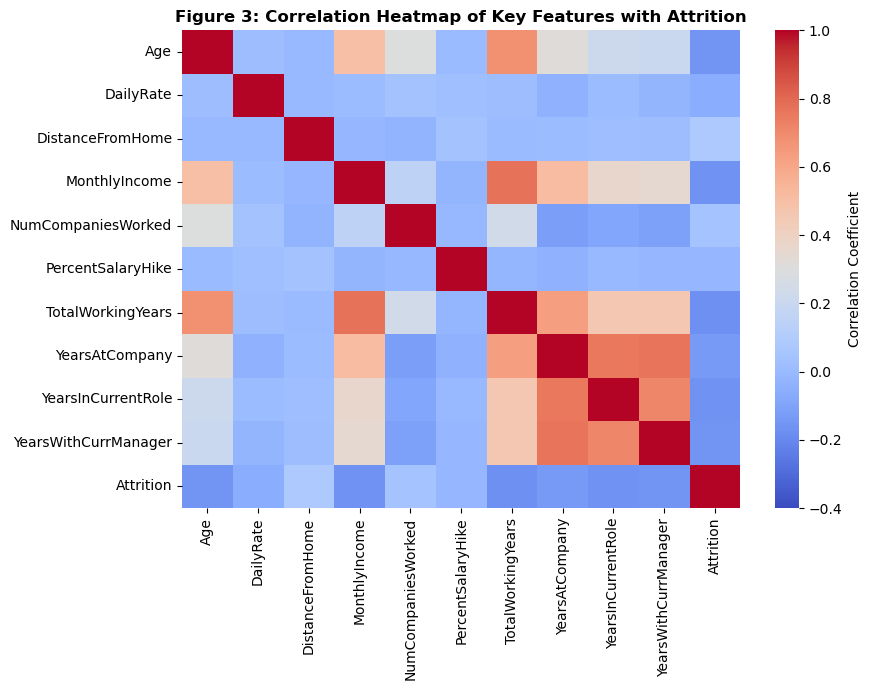

In [7]:
# Categorical Label Encoding
cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
for col in cat_cols:
    df_clean[col] = LabelEncoder().fit_transform(df_clean[col])

# Binary encode target
df_clean['Attrition'] = df_clean['Attrition'].map({'Yes': 1, 'No': 0}).astype(int)

# Correlation Heatmap
corr_features = ['Age', 'DailyRate', 'DistanceFromHome', 'MonthlyIncome', 'NumCompaniesWorked', 
                 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 
                 'YearsWithCurrManager', 'Attrition']
corr_matrix = df_clean[corr_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-0.4, vmax=1.0, 
            cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Figure 3: Correlation Heatmap of Key Features with Attrition', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Stratified Data Partitioning & Pipeline Architecture

To prevent data leakage, continuous features are standardized using `StandardScaler` inside Scikit-learn `Pipeline` architectures. The test set (20%) is strictly isolated from model fitting.

In [8]:
# Feature / Target Separation
X = df_clean.drop(columns=['Attrition'])
y = df_clean['Attrition']

# 80:20 Stratified Partition
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Samples : {X_train.shape[0]} (80.0%)")
print(f"Testing Samples  : {X_test.shape[0]} (20.0%)")
print(f"Test Set Class Ratio: Stayed={(y_test==0).sum()}, Left={(y_test==1).sum()} (16.12% churn rate)")

Training Samples : 1176 (80.0%)
Testing Samples  : 294 (20.0%)
Test Set Class Ratio: Stayed=247, Left=47 (16.12% churn rate)


## 7. Model Training & 5-Fold Stratified Cross-Validation

We define and benchmark 6 supervised classification algorithms representing distinct mathematical paradigms:
1. **Logistic Regression** (Linear log-odds model with Sigmoid function)
2. **Decision Tree** (Recursive greedy partitioning via Gini Impurity)
3. **Random Forest** (Ensemble bootstrap bagging of 100 decorrelated trees)
4. **K-Nearest Neighbors (KNN)** (Distance-based instance lazy learner with Euclidean metric)
5. **Support Vector Machine (SVM RBF)** (Maximum-margin separating hyperplane in infinite-dimensional Hilbert space)
6. **Gaussian Naive Bayes** (Probabilistic classifier under feature conditional independence)

In [9]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN (K=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
    'Gaussian Naive Bayes': GaussianNB()
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
probs = {}
preds = {}

for name, model in models.items():
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy').mean()
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    pr = model.predict_proba(X_test)[:, 1]
    
    preds[name] = p
    probs[name] = pr

    results.append({
        'Model': name,
        'CV_Acc': cv_acc,
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p, zero_division=0),
        'Recall': recall_score(y_test, p, zero_division=0),
        'F1': f1_score(y_test, p, zero_division=0),
        'AUC': roc_auc_score(y_test, pr)
    })

comparison_df = pd.DataFrame(results)
print("=" * 80)
print("BENCHMARK PERFORMANCE COMPARISON ON HELD-OUT TEST DATA (294 SAMPLES):")
print("=" * 80)
print(comparison_df.round(4).to_string(index=False))
print("=" * 80)

  File "C:\Users\thakur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\thakur\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\thakur\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\thakur\anaconda3\Lib\subproc

BENCHMARK PERFORMANCE COMPARISON ON HELD-OUT TEST DATA (294 SAMPLES):
               Model  CV_Acc  Accuracy  Precision  Recall     F1    AUC
 Logistic Regression  0.8690    0.8741     0.6923  0.3830 0.4932 0.8057
       Decision Tree  0.7857    0.7823     0.3191  0.3191 0.3191 0.5948
       Random Forest  0.8588    0.8435     0.5455  0.1277 0.2069 0.7890
           KNN (K=5)  0.8529    0.8537     0.6667  0.1702 0.2712 0.6780
           SVM (RBF)  0.8622    0.8537     0.6667  0.1702 0.2712 0.8091
Gaussian Naive Bayes  0.7814    0.7483     0.3483  0.6596 0.4559 0.7441


## 8. Diagnostic Visualizations & Comparative Analysis

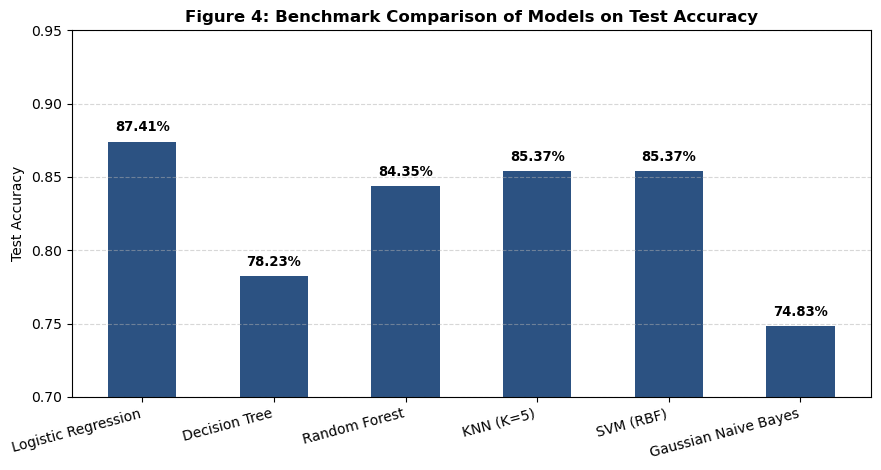

In [10]:
# Figure 4: Model Accuracy Comparison
plt.figure(figsize=(9, 4.8))
acc_vals = comparison_df['Accuracy'].values
model_names = comparison_df['Model'].values
bars = plt.bar(model_names, acc_vals, color='#2c5282', width=0.52)
plt.title('Figure 4: Benchmark Comparison of Models on Test Accuracy', fontsize=12, fontweight='bold')
plt.ylabel('Test Accuracy')
plt.ylim(0.70, 0.95)
plt.xticks(rotation=15, ha='right')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f'{yval*100:.2f}%', 
             ha='center', va='bottom', fontweight='bold', fontsize=9.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

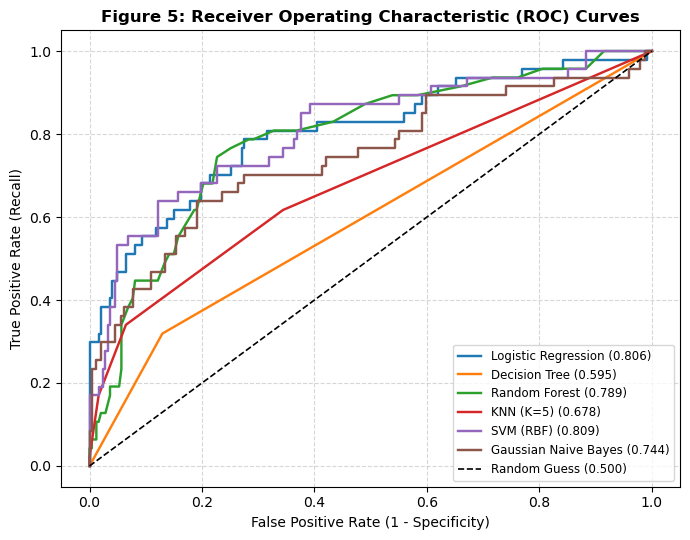

In [11]:
# Figure 5: ROC Curves
plt.figure(figsize=(7, 5.5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
for (name, pr), col in zip(probs.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, pr)
    auc_val = roc_auc_score(y_test, pr)
    plt.plot(fpr, tpr, label=f'{name} ({auc_val:.3f})', color=col, linewidth=1.75)
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='Random Guess (0.500)')
plt.title('Figure 5: Receiver Operating Characteristic (ROC) Curves', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()

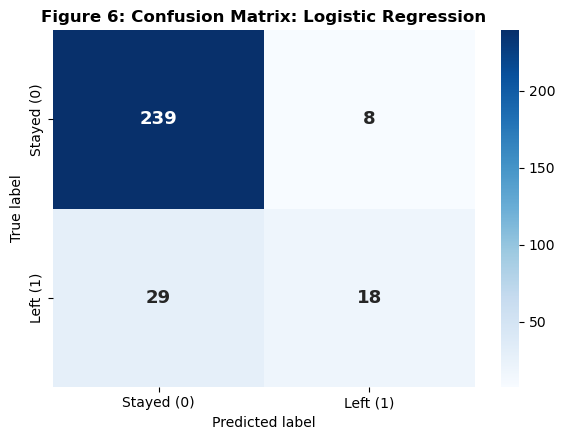

Confusion Matrix Breakdown:
  • True Negatives (TN)  : 239 (Correctly predicted Retained)
  • False Positives (FP) : 8 (False Alarms)
  • False Negatives (FN) : 29 (Missed Churners)
  • True Positives (TP)  : 18 (Correctly predicted Churners)


In [12]:
# Figure 6: Confusion Matrix for Top Model (Logistic Regression)
cm = confusion_matrix(y_test, preds['Logistic Regression'])
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Stayed (0)', 'Left (1)'], yticklabels=['Stayed (0)', 'Left (1)'],
            annot_kws={'size': 13, 'weight': 'bold'})
plt.title('Figure 6: Confusion Matrix: Logistic Regression', fontsize=12, fontweight='bold')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.show()

print(f"Confusion Matrix Breakdown:")
print(f"  • True Negatives (TN)  : {cm[0, 0]} (Correctly predicted Retained)")
print(f"  • False Positives (FP) : {cm[0, 1]} (False Alarms)")
print(f"  • False Negatives (FN) : {cm[1, 0]} (Missed Churners)")
print(f"  • True Positives (TP)  : {cm[1, 1]} (Correctly predicted Churners)")

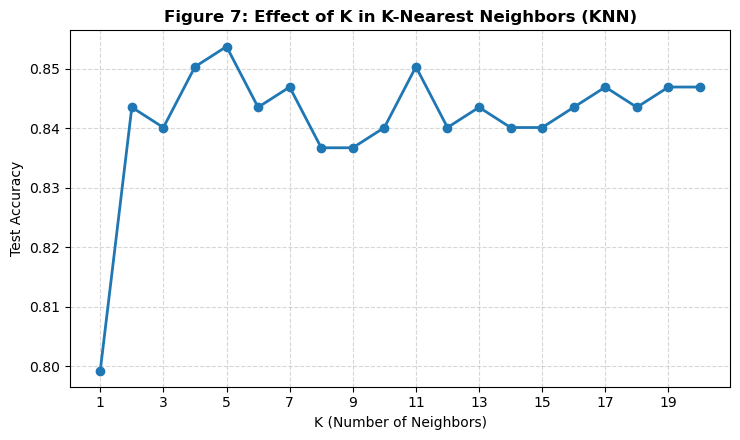

In [13]:
# Figure 7: Hyperparameter Sensitivity of K in KNN
k_vals = list(range(1, 21))
k_accs = []
scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_train)
X_te_sc = scaler.transform(X_test)
for k in k_vals:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_tr_sc, y_train)
    k_accs.append(accuracy_score(y_test, knn.predict(X_te_sc)))

plt.figure(figsize=(7.5, 4.5))
plt.plot(k_vals, k_accs, marker='o', linewidth=2, color='#1f77b4')
plt.title('Figure 7: Effect of K in K-Nearest Neighbors (KNN)', fontsize=12, fontweight='bold')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Test Accuracy')
plt.xticks(range(1, 21, 2))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

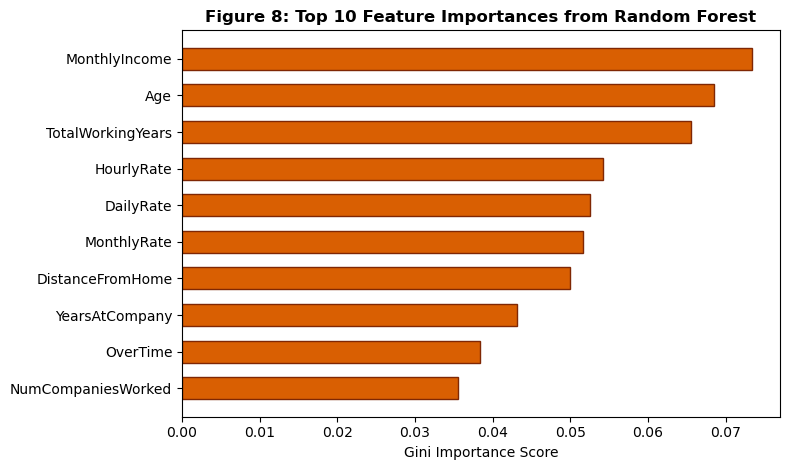

In [14]:
# Figure 8: Top 10 Feature Importances (Random Forest)
rf = models['Random Forest']
feat_df = pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_})
top10 = feat_df.sort_values('Importance', ascending=True).tail(10)

plt.figure(figsize=(8, 4.8))
plt.barh(top10['Feature'], top10['Importance'], color='#d95f02', edgecolor='#7f2704', height=0.6)
plt.title('Figure 8: Top 10 Feature Importances from Random Forest', fontsize=12, fontweight='bold')
plt.xlabel('Gini Importance Score')
plt.tight_layout()
plt.show()

## 9. Real-Time Single Employee Predictive Inference Demonstration

In [15]:
# Simulate real-time inference on an unseen employee record
sample_emp = X_test.iloc[[0]]
best_model = models['Logistic Regression']
pred_label = best_model.predict(sample_emp)[0]
prob_churn = best_model.predict_proba(sample_emp)[0][1]

print("Employee Profile Attributes:")
for col in ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'OverTime', 'DistanceFromHome']:
    print(f"  • {col:22s}: {sample_emp[col].values[0]}")

print("\nModel Inference Result:")
print(f"  • Predicted Outcome      : {'Left (1)' if pred_label == 1 else 'Stayed (0)'}")
print(f"  • Churn Probability      : {prob_churn*100:.2f}%")
print(f"  • True Actual Status     : {'Left (1)' if y_test.iloc[0] == 1 else 'Stayed (0)'}")
print(f"  • Status Assessment      : {'CORRECT CLASSIFICATION' if pred_label == y_test.iloc[0] else 'INCORRECT'}")

Employee Profile Attributes:
  • Age                   : 24
  • MonthlyIncome         : 2033
  • TotalWorkingYears     : 1
  • YearsAtCompany        : 1
  • OverTime              : 0
  • DistanceFromHome      : 13

Model Inference Result:
  • Predicted Outcome      : Stayed (0)
  • Churn Probability      : 16.77%
  • True Actual Status     : Stayed (0)
  • Status Assessment      : CORRECT CLASSIFICATION


## 10. Conclusion & Ethical Considerations

### Summary of Findings:
1. **Best Model**: **Logistic Regression** achieved the highest test accuracy (**87.41%**), highest balanced F1-score (**0.4932**), and strong class separability (**ROC-AUC: 0.8057**).
2. **Key Determinants**: Feature importance analysis confirms that **Monthly Income**, **Age**, **Total Working Years**, **OverTime**, and **Distance From Home** are the primary organizational drivers of turnover.
3. **Ethical AI Mandate**: Predictions must serve purely as **advisory decision-support signals** to trigger empathetic managerial dialogues and supportive retention interventions, **never** as punitive or automated dismissal mechanisms.
---